Demonstrate Discrete and Continuous Random Variables (Binomial and Normal Distributions)

Enter the value of n: 5
Enter the value of p: 0.5
The answer is: [0.03125, 0.15625, 0.3125, 0.3125, 0.15625, 0.03125]


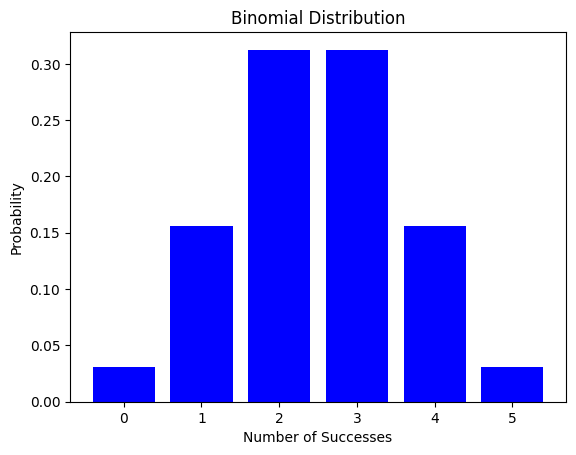

In [1]:
import matplotlib.pyplot as plt
def fac(n):
    if n==1 or n==0:
        return 1
    else:
        return n*fac(n-1)

def bio(n,p):
    pro = []
    q=1-p
    for r in range(0,n+1):
        b= (fac(n)/(fac(r)*fac(n-r)))*(p**r)*(q**(n-r))
        pro.append(b)

    return pro

n=int(input("Enter the value of n: "))
p=float(input("Enter the value of p: "))
ans=bio(n,p)
print("The answer is:",ans)

plt.bar(range(0, n+1), ans, color='blue')
plt.xlabel('Number of Successes')
plt.ylabel('Probability')
plt.title('Binomial Distribution')
plt.show()


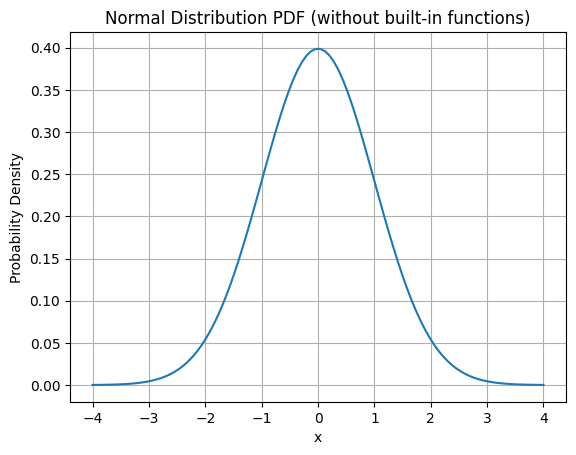

In [2]:
import math
import numpy as np
import matplotlib.pyplot as plt

def normal_pdf(x, mu, sigma):
  coeff = 1/ (sigma * ( (2*(22/7))**0.5))
  exponent = -((x-mu) ** 2) / (2 * sigma ** 2)
  return coeff * math.exp(exponent)

mu = 0
sigma = 1
# Generate x values
x_values = np.linspace(-4,4,100)
pdf_values = [normal_pdf(x, mu, sigma) for x in x_values]

# Plotting
plt.plot(x_values, pdf_values)
plt.title('Normal Distribution PDF (without built-in functions)')
plt.xlabel('x')
plt.ylabel('Probability Density')
plt.grid(True)
plt.show()

Implement Joint Probability Mass Function

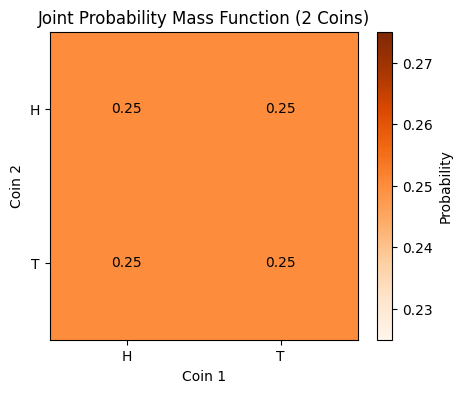

In [3]:
import numpy as np
import matplotlib.pyplot as plt

coin_outcomes = ["H", "T"]

# Create a 2x2 matrix for the joint PMF
joint_pmf = np.zeros((2, 2))

# Each outcome (H,H), (H,T), (T,H), (T,T) has equal probability = 1/4
for i in range(2):
    for j in range(2):
        joint_pmf[i, j] = 1 / 4

# Plotting the PMF
plt.figure(figsize=(5, 4))
plt.imshow(joint_pmf, cmap="Oranges", interpolation="nearest")

# Display probability values inside the boxes
for i in range(2):
    for j in range(2):
        plt.text(j, i, round(joint_pmf[i, j], 2), ha='center', va='center')


plt.title("Joint Probability Mass Function (2 Coins)")
plt.xlabel("Coin 1")
plt.ylabel("Coin 2")
plt.xticks(np.arange(2), coin_outcomes)
plt.yticks(np.arange(2), coin_outcomes)
plt.colorbar(label="Probability")
plt.show()


mplement central limit theorem and plot probability distribution

/tmp/ipython-input-1639960883.py:37: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


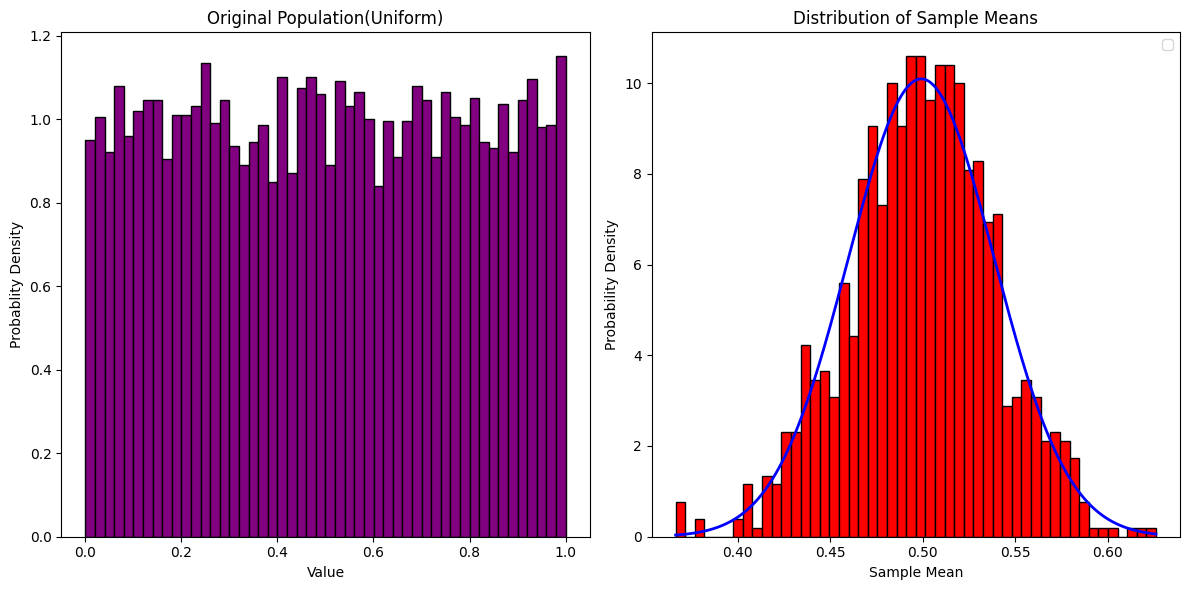

In [4]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm


population=np.random.uniform(0,1,10000)

sample_size=50
num_sample=1000
sample_means=[]

for _ in range(num_sample):
    sample=np.random.choice(population,size=sample_size,replace=True)
    sample_means.append(np.mean(sample))

plt.figure(figsize=(12,6))

plt.subplot(1,2,1)
plt.hist(population,bins=50,color="purple",edgecolor='black',density=True)
plt.title("Original Population(Uniform)")
plt.xlabel("Value")
plt.ylabel("Probablity Density")

plt.subplot(1,2,2)
plt.hist(sample_means,bins=50,color="Red",edgecolor='black',density=True)

mean=np.mean(sample_means)
std=np.std(sample_means)

x=np.linspace(min(sample_means),max(sample_means),1000)
pdf=norm.pdf(x,mean,std)
plt.plot(x,pdf,color='blue',linewidth=2)
plt.title("Distribution of Sample Means")
plt.xlabel("Sample Mean")
plt.ylabel("Probability Density")
lable="Normal Distribution(CLT Prediction)"
plt.legend()
plt.tight_layout()
plt.show()





Generate t & f distribution

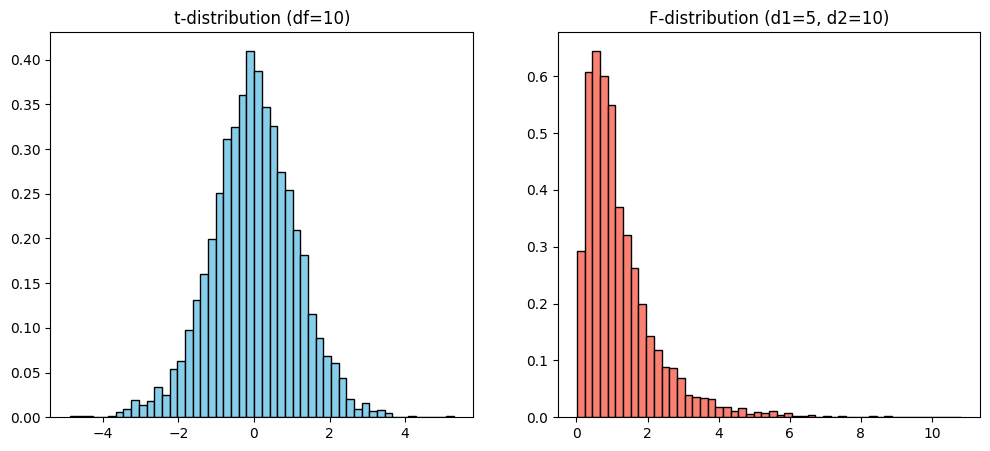

In [5]:
import random
import math
import matplotlib.pyplot as plt

def normal_random():
    return sum(random.random() for _ in range(12)) - 6

def t_random(df):
    z = normal_random()
    v = sum(normal_random()**2 for _ in range(df))
    return z / math.sqrt(v / df)

def f_random(d1, d2):
    u = sum(normal_random()**2 for _ in range(d1)) / d1
    v = sum(normal_random()**2 for _ in range(d2)) / d2
    return u / v

def generate_samples(func, n, *args):
    return [func(*args) for _ in range(n)]

t_samples = generate_samples(t_random, 5000, 10)

f_samples = generate_samples(f_random, 5000, 5, 10)

plt.figure(figsize=(12,5))
# t-distribution
plt.subplot(1,2,1)
plt.hist(t_samples, bins=50, density=True, color="skyblue", edgecolor="black")
plt.title("t-distribution (df=10)")
# F-distribution
plt.subplot(1,2,2)
plt.hist(f_samples, bins=50, density=True, color="salmon", edgecolor="black")
plt.title("F-distribution (d1=5, d2=10)")
plt.show()